<a href="https://colab.research.google.com/github/mohany606/Linear-Models-and-Support-Vector-Machines-from-Scratch/blob/main/ML_Assigmment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part A: Data:**

In [15]:
# @title
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_digits,
    load_iris
)
# 1. Diabetes
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target
# 2. Breast Cancer
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = 1 - cancer.target  # Malignant = 1
# 3. Digits
digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target
# 4. Iris
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
def split_data(X, y, regression=False):
    stratify = None if regression else y
    # First split
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify
    )
    # Second split
    stratify_temp = None if regression else y_temp

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_temp
    )

    return X_train, X_val, X_test, y_train, y_val, y_test


In [16]:
# @title
datasets = {
    "Diabetes": (X_diabetes, y_diabetes, True),
    "Breast Cancer": (X_cancer, y_cancer, False),
    "Digits": (X_digits, y_digits, False),
    "Iris": (X_iris, y_iris, False)
}

splits = {}

for name, (X, y, regression) in datasets.items():
    splits[name] = split_data(X, y, regression)

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]
    print(f"\n{name}")
    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)

    if not regression:
        print("Train class counts:", np.bincount(y_train))
        print("Validation class counts:", np.bincount(y_val))
        print("Test class counts:", np.bincount(y_test))



Diabetes
Train: (264, 10)
Validation: (89, 10)
Test: (89, 10)

Breast Cancer
Train: (341, 30)
Validation: (114, 30)
Test: (114, 30)
Train class counts: [214 127]
Validation class counts: [71 43]
Test class counts: [72 42]

Digits
Train: (1077, 64)
Validation: (360, 64)
Test: (360, 64)
Train class counts: [106 109 107 109 109 109 109 107 104 108]
Validation class counts: [36 37 35 37 36 36 36 36 35 36]
Test class counts: [36 36 35 37 36 37 36 36 35 36]

Iris
Train: (90, 4)
Validation: (30, 4)
Test: (30, 4)
Train class counts: [30 30 30]
Validation class counts: [10 10 10]
Test class counts: [10 10 10]


In [17]:
# @title

class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)

        #each column feature
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1
        return self
    def transform(self, X):
        return (X - self.mean) / self.std

scaler = Standardizer()
#Why not call fit() separately for validation and testing?
#Because that would mean using different means and standard deviations for different sets.
#We want all three sets to use the same transformation.

def add_bias(X):
    return np.c_[np.ones(X.shape[0]), X]

# Preprocess each dataset separately
processed_data = {}
scalers = {}
for name in datasets:

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]

    if name == "Digits":
        # Digits are already divided by 16.
        # NO standardize them.
        X_train_processed = X_train
        X_val_processed = X_val
        X_test_processed = X_test

    else:
        # Fit using training data only
        scaler = Standardizer()
        scaler.fit(X_train)

        X_train_processed = scaler.transform(X_train)
        X_val_processed = scaler.transform(X_val)
        X_test_processed = scaler.transform(X_test)

        scalers[name] = scaler

        train_mean = np.mean(X_train_processed, axis=0)
        train_std = np.std(X_train_processed, axis=0)

        print(f"\n{name} Standardizer verification:")
        print("Maximum absolute training mean:",
              np.max(np.abs(train_mean)))
        print("Training standard deviations:", train_std)

    # Add bias to all three splits
    X_train_final = add_bias(X_train_processed)
    X_val_final = add_bias(X_val_processed)
    X_test_final = add_bias(X_test_processed)

    # Save everything together
    processed_data[name] = (
        X_train_final,
        X_val_final,
        X_test_final,
        y_train,
        y_val,
        y_test
    )

print("\nAll datasets preprocessed successfully.")





Diabetes Standardizer verification:
Maximum absolute training mean: 2.2372676102294822e-15
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Breast Cancer Standardizer verification:
Maximum absolute training mean: 5.108979384873301e-15
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris Standardizer verification:
Maximum absolute training mean: 1.2927930331190711e-15
Training standard deviations: [1. 1. 1. 1.]

All datasets preprocessed successfully.


In [18]:
# @title
#mean squared error
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)
#Root Mean Squared Error
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))
#R² — Coefficient of Determination
def r2(y_true, y_pred):
    s = np.sum((y_true - y_pred) ** 2)
    sm = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (s / sm)
#Accuracy
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)
#Confusion Matrix
def confusion_matrix(y_true, y_pred, m):#m:number  of classes
    cm = np.zeros((m, m), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)#y_true, y_pred:m[i,j]
    return cm

def classification_metrics(cm):
    K = cm.shape[0]
    # True positives: diagonal
    TP = np.diag(cm)

    # Total predicted (column sums) TP+FP
    predicted = np.sum(cm, axis=0)

    # Total actual (row sums)TP+Fn
    actual = np.sum(cm, axis=1)

    # Precision
    # If a class is never predicted, precision = 0
    precision = np.divide(
        TP,
        predicted,
        out=np.zeros(K, dtype=float),
        where=predicted != 0
    )

    # Recall
    recall = np.divide(
        TP,
        actual,
        out=np.zeros(K, dtype=float),
        where=actual != 0
    )

    # F1-score
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(K, dtype=float),
        where=(precision + recall) != 0
    )

    # Macro averages
    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }



In [19]:
# @title
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

# Generate random classification labels
K = 4
N = 500

y_true = rng.integers(0, K, size=N)
y_pred = rng.integers(0, K, size=N)


cm = confusion_matrix(y_true, y_pred, K)
cm_sk = sk_confusion_matrix(
    y_true, y_pred,
    labels=np.arange(K) #[0, 1, 2, 3]
)

assert np.array_equal(cm, cm_sk) #If yes, the code continues.
#If no, Python raises an AssertionError and stops.


acc = accuracy(y_true, y_pred)
acc_sk = accuracy_score(y_true, y_pred)

assert abs(acc - acc_sk) < 1e-12 #tolerance error


our_metrics = classification_metrics(cm)

# sklearn metrics
p_sk, r_sk, f1_sk, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)
#np.allclose() compares two arrays element by element
assert np.allclose(our_metrics["precision"], p_sk, atol=1e-12)

assert np.allclose(our_metrics["recall"], r_sk, atol=1e-12)

assert np.allclose(our_metrics["f1"], f1_sk, atol=1e-12)

assert abs(our_metrics["macro_precision"] - np.mean(p_sk)) < 1e-12

assert abs( our_metrics["macro_recall"] - np.mean(r_sk)) < 1e-12

assert abs( our_metrics["macro_f1"] - np.mean(f1_sk)) < 1e-12

print("All classification metrics ")

# Generate random regression values
y_true_reg = rng.normal(size=500)
y_pred_reg = rng.normal(size=500)

# MSE
our_mse = mse(y_true_reg, y_pred_reg)
sk_mse = mean_squared_error(y_true_reg, y_pred_reg)

# RMSE
our_rmse = rmse(y_true_reg, y_pred_reg)
sk_rmse = np.sqrt(sk_mse)

# R2
our_r2 = r2(y_true_reg, y_pred_reg)
sk_r2 = r2_score(y_true_reg, y_pred_reg)

assert abs(our_mse - sk_mse) < 1e-12
assert abs(our_rmse - sk_rmse) < 1e-12
assert abs(our_r2 - sk_r2) < 1e-12

print("All regression metrics")



All classification metrics 
All regression metrics


In [20]:
# @title
def grad_check(f, grad, w, eps=1e-5, num_checks=None):

    # Calculate analytical gradient
    g_analytic = grad(w)

    #with the same shape as w, but filled with zeros.
    g_numeric = np.zeros_like(w, dtype=float)

    # It converts an array into a one-dimensional array.
    w_flat = w.reshape(-1)
    g_flat = g_numeric.reshape(-1)
    #If the user doesn't specify how many weights to check,
    #or requests at least as many checks as there are weights, check all weights.
    if num_checks is None or num_checks >= w.size:
        indices = np.arange(w.size)
    else:
        rng = np.random.default_rng(42)
        indices = rng.choice(
            w.size,
            size=num_checks,
            replace=False
        )

    #numerical gradient
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps
        g_flat[i] = (f(w_plus) - f(w_minus) ) / (2 * eps)

    # Compare only the selected entries
    analytic_selected = g_analytic.flat[indices]
    numeric_selected = g_numeric.flat[indices]

    # np.linalg.norm() calculates the Euclidean length of this difference
    numerator = np.linalg.norm(
        analytic_selected - numeric_selected
    )

    denominator = max(
        np.linalg.norm(analytic_selected),
        np.linalg.norm(numeric_selected),
        1e-12
    )

    relative_error = numerator / denominator

    return relative_error


# **Part B :Linear Regression:**

In [21]:
# @title
import pandas as pd
from sklearn.linear_model import LinearRegression

#getting the processed data for the Diabetes dataset
X_train_final, X_val_final, X_test_final, y_train, y_val, y_test = processed_data["Diabetes"]
#5 closed form solution
def normal_equation(X, y):
    A = X.T @ X
    b = X.T @ y
    w = np.linalg.solve(A, b) #solve sys of linear equations
    return w

# calculated the opt weights
w_normal = normal_equation(X_train_final, y_train)
print("Normal Equation Weights:")
print(w_normal)
#get el predictions
y_train_pred = X_train_final @ w_normal
y_val_pred = X_val_final @ w_normal
y_test_pred = X_test_final @ w_normal
print("Train RMSE:", rmse(y_train, y_train_pred))
print("Validation RMSE:", rmse(y_val, y_val_pred))
print("Test RMSE:", rmse(y_test, y_test_pred))
print("Test R2:", r2(y_test, y_test_pred))

feature_names = ["Bias"] + list(diabetes.feature_names)
weights_table = pd.DataFrame({"Feature": feature_names, "Weight": w_normal})
print(weights_table)

condition_number = np.linalg.cond(X_train_final.T @ X_train_final)
print("Condition Number:", condition_number)


Normal Equation Weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Train RMSE: 54.6103635732402
Validation RMSE: 51.1937139785339
Test RMSE: 54.15641293326043
Test R2: 0.4464263764021127
   Feature      Weight
0     Bias  149.810606
1      age    1.131837
2      sex  -11.359311
3      bmi   25.076618
4       bp   15.167338
5       s1  -51.101359
6       s2   27.480823
7       s3   10.840294
8       s4   15.032148
9       s5   37.271588
10      s6    3.817112
Condition Number: 505.7061226960868


In [22]:
# @title
#verify the results using sklearn's LinearRegression
model = LinearRegression()

model.fit(X_train_final[:, 1:], y_train)

sklearn_weights = np.concatenate((
    [model.intercept_],
    model.coef_
))

print("my weights:")
print(w_normal)

print("Sklearn weights:")
print(sklearn_weights)

print("Maximum absolute difference:",
      np.max(np.abs(w_normal - sklearn_weights)))

assert np.allclose(w_normal, sklearn_weights, atol=1e-6)

my weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Sklearn weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Maximum absolute difference: 1.1510792319313623e-12


 Interpretation of Selected Coefficients

BMI (+25.08):The positive value means that when BMI increases, the predicted target value also tends to increase, assuming the other features stay the same

s1 (-51.10):The negative value means that when s1 increases, the predicted target value tends to decrease, while keeping the other features constant

s2 (+27.48):The positive value means that when s2 increases, the predicted target value also tends to increase, assuming the other features stay the same

Although s1 and s2 are related features, they have different coefficient signs. This is because the model considers all features together when calculating the weights. So, the effect of one feature can be influenced by the other features

These results show relationships between the features and the target, but they do not mean that one feature directly causes the target to increase or decrease

In [23]:
# @title
#6 Gradient descent

def batch_gradient_descent(X, y, learning_rate, epochs):
    N = X.shape[0]
    # intialize weights to zeros
    w = np.zeros(X.shape[1])
    losses = []
    distances = []
    for epoch in range(epochs):
        # Calculate y^
        y_pred = X @ w
        #gradient
        gradient = (X.T @ (y_pred - y)) / N
        # Update w
        w = w - learning_rate * gradient
        # Calc loss
        y_pred = X @ w
        loss = np.sum((y_pred - y) ** 2) / (2 * N)
        losses.append(loss)
        # Compare current weights with Normal Equation weights
        distance = np.linalg.norm(w - w_normal) / np.linalg.norm(w_normal)
        distances.append(distance)
    return w, losses, distances
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_results = {}

for n in learning_rates:
    w, losses, distances = batch_gradient_descent(X_train_final,y_train,n,epochs=2000)
    gd_results[n] = {"weights": w,"losses": losses,"distances": distances}
    print(f"\nLearning rate: {n}")
    print("Final loss:", losses[-1])
    print("Final relative distance:", distances[-1])


Learning rate: 0.001
Final loss: 1723.4028887869279
Final relative distance: 0.4051130510143055

Learning rate: 0.01
Final loss: 1503.6866758289357
Final relative distance: 0.3345214298368573

Learning rate: 0.1
Final loss: 1491.8926356565873
Final relative distance: 0.08179228655115486

Learning rate: 0.5
Final loss: 1491.1459074694744
Final relative distance: 0.0001546261648138314

Learning rate: 1.0
Final loss: nan
Final relative distance: nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_1170/34626843.py:19: RuntimeWarning: overflow encountered in square
  loss = np.sum((y_pred - y) ** 2) / (2 * N)
/usr/local/lib/python3.13/dist-packages/numpy/linalg/_linalg.py:2768: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
/tmp/ipykernel_1170/34626843.py:14: RuntimeWarning: overflow encountered in matmul
  gradient = (X.T @ (y_pred - y)) / N
/tmp/ipykernel_1170/34626843.py:18: RuntimeWarning: invalid value encountered in matmul
  y_pred = X @ w
/tmp/ipykernel_1170/34626843.py:12: RuntimeWarning: invalid value encountered in matmul
  y_pred = X @ w
/tmp/ipykernel_1170/34626843.py:14: RuntimeWarning: invalid value encountered in matmul
  gradient = (X.T @ (y_pred - y)) / N


In [24]:
# @title
results_table = []
for n in learning_rates:
    distances = gd_results[n]["distances"]
    losses = gd_results[n]["losses"]
    # Find the first epoch where distance < 0.001
    reached = np.where(np.array(distances) < 1e-3)[0]
    if len(reached) > 0:
        first_epoch = reached[0] + 1
    else:
        first_epoch = "Not reached"
    results_table.append({"Learning Rate": n,"Final Loss": losses[-1],"Final Relative Distance": distances[-1],"First Epoch < 1e-3": first_epoch })
results_df = pd.DataFrame(results_table)
print(results_df)

   Learning Rate   Final Loss  Final Relative Distance First Epoch < 1e-3
0          0.001  1723.402889                 0.405113        Not reached
1          0.010  1503.686676                 0.334521        Not reached
2          0.100  1491.892636                 0.081792        Not reached
3          0.500  1491.145907                 0.000155               1524
4          1.000          NaN                      NaN        Not reached


I tested different learning rates to see the effect on Gradient Descent. Smaller learning rates need more time to reach the optimal weights because the updates are small. When I used 0.5, the algorithm converged and reached a relative distance below 0.001 at epoch 1524. However, when I used 1.0, the algorithm diverged because the updates were too large. This shows that choosing a suitable learning rate is important for Gradient Descent.

In [25]:
# @title
#testing the data
for n in learning_rates:
    losses = np.array(gd_results[n]["losses"])
    print(n,"Valid values:", np.sum(np.isfinite(losses) & (losses > 0)),"First loss:", losses[0],"Last loss:", losses[-1] )

0.001 Valid values: 2000 First loss: 14298.909044618456 Last loss: 1723.4028887869279
0.01 Valid values: 2000 First loss: 14021.69815217566 Last loss: 1503.6866758289357
0.1 Valid values: 2000 First loss: 11480.75212086384 Last loss: 1491.8926356565873
0.5 Valid values: 2000 First loss: 5272.72341276293 Last loss: 1491.1459074694744
1.0 Valid values: 321 First loss: 9187.581119362443 Last loss: nan


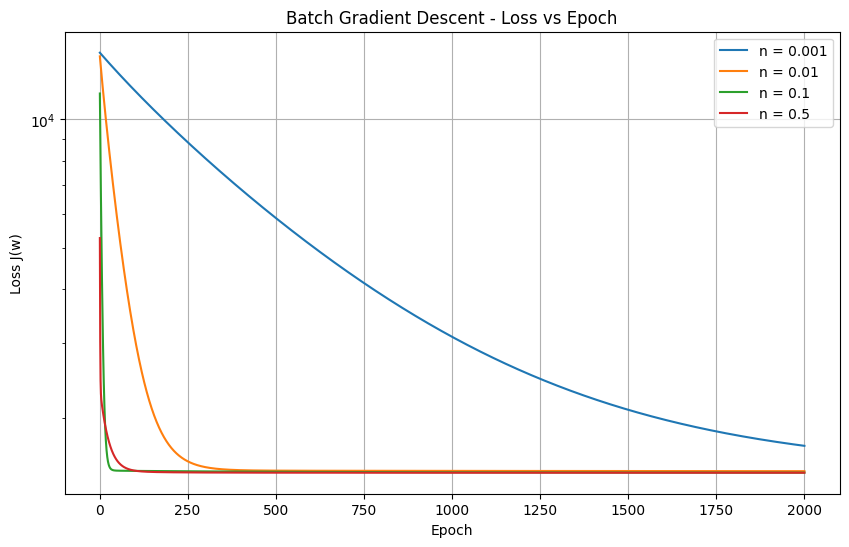

In [26]:
# @title
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

for n in [0.001, 0.01, 0.1, 0.5]:
    losses = gd_results[n]["losses"]
    plt.plot(range(1, 2001), losses, label=f"n = {n}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss J(w)")
plt.title("Batch Gradient Descent - Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

i exclucde n=1.0 because loss is extremly large so it  made the other curves hard to read

In [27]:
# @title
N=X_train_final.shape[0]
H=(X_train_final.T @ X_train_final)/N
eigenvalues=np.linalg.eigvalsh(H)
lambda_max=np.max(eigenvalues)
print("Largest eigenvalue:", lambda_max)
n_max = 2 / lambda_max
print("Maximum theoretical learning rate:", n_max)
#testing 2 diff learningrates around threshold
n_below = 0.95 * (2 / lambda_max)
n_above = 1.05 * (2 / lambda_max)
print("Learning rate below threshold:", n_below)
print("Learning rate above threshold:", n_above)

Largest eigenvalue: 3.9547550320503744
Maximum theoretical learning rate: 0.5057203249737277
Learning rate below threshold: 0.4804343087250412
Learning rate above threshold: 0.5310063412224141


# **Part C : Logistic Regression:**

#11-Derivation and stable implementation:

In [28]:
X_train, X_val, X_test, y_train, y_val, y_test = processed_data["Breast Cancer"]
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Train labels:", np.unique(y_train, return_counts=True))

Train: (341, 31)
Validation: (114, 31)
Test: (114, 31)
Train labels: (array([0, 1]), array([214, 127]))


In [29]:
def sigmoid(z):
    result = np.empty_like(z, dtype=float)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result

def logistic_loss(X, y, w, lam):
    z = X @ w
    loss = np.mean(np.logaddexp(0, z) - y * z)
    reg = (lam / 2) * np.sum(w[1:] ** 2)
    return loss + reg

def logistic_gradient(X, y, w, lam):
    p = sigmoid(X @ w)
    grad = X.T @ (p - y) / len(y)
    grad[1:] += lam * w[1:]
    return grad

In [30]:
z = np.array([800.0, -800.0])
y_test_values = np.array([1.0, 0.0])
p = sigmoid(z)
stable_loss = np.logaddexp(0, z) - y_test_values * z

print("Sigmoid:", p)
print("Stable loss:", stable_loss)

with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
    naive_p = 1 / (1 + np.exp(-z))
    naive_loss = -(
        y_test_values * np.log(naive_p) +
        (1 - y_test_values) * np.log(1 - naive_p)
    )
print("Naive probabilities:", naive_p)
print("Naive loss:", naive_loss)

Sigmoid: [1. 0.]
Stable loss: [0. 0.]
Naive probabilities: [1. 0.]
Naive loss: [nan nan]


In [31]:
rng = np.random.default_rng(42)
w_random = rng.normal(0, 0.1, X_train.shape[1])
lam = 0.1
f = lambda w: logistic_loss(X_train, y_train, w, lam)
grad = lambda w: logistic_gradient(X_train, y_train, w, lam)
error = grad_check(f, grad, w_random)
print("Gradient relative error:", error)

Gradient relative error: 1.899324633360124e-11


#12-Training and regularization:

In [32]:
def train_logistic(X_train, y_train, X_val, y_val,lam, learning_rate, epochs):
    w = np.zeros(X_train.shape[1])
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):
        grad = logistic_gradient(X_train, y_train, w, lam)
        w = w - learning_rate * grad

        train_loss = logistic_loss(X_train, y_train, w, lam)
        val_loss = logistic_loss(X_val, y_val, w, lam)

        train_pred = (sigmoid(X_train @ w) >= 0.5).astype(int)
        val_pred = (sigmoid(X_val @ w) >= 0.5).astype(int)

        train_acc = accuracy(y_train, train_pred)
        val_acc = accuracy(y_val, val_pred)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

    return w, train_losses, val_losses, train_accuracies, val_accuracies

In [33]:
lambdas = [0, 1e-3, 1e-2, 1e-1, 1]
results = {}
for lam in lambdas:
    w, train_losses, val_losses, train_accs, val_accs = train_logistic(
        X_train, y_train,
        X_val, y_val,
        lam=lam,
        learning_rate=0.5,
        epochs=3000
    )
    results[lam] = {
        "w": w,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }
print("All lambda experiments completed.")

All lambda experiments completed.


In [34]:
for lam in lambdas:
    w = results[lam]["w"]

    train_pred = (sigmoid(X_train @ w) >= 0.5).astype(int)
    val_pred = (sigmoid(X_val @ w) >= 0.5).astype(int)

    train_acc = accuracy(y_train, train_pred)
    val_acc = accuracy(y_val, val_pred)

    val_loss = results[lam]["val_losses"][-1]

    weight_norm = np.linalg.norm(w[1:])

    print(f"\nLambda = {lam}")
    print("Train Accuracy:", train_acc)
    print("Validation Accuracy:", val_acc)
    print("Validation Loss:", val_loss)
    print("||w[1:]||:", weight_norm)


Lambda = 0
Train Accuracy: 0.9941348973607038
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.08419249601904283
||w[1:]||: 8.132231477398316

Lambda = 0.001
Train Accuracy: 0.9882697947214076
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.08620739680111857
||w[1:]||: 5.099928324496716

Lambda = 0.01
Train Accuracy: 0.9853372434017595
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.11000996461449458
||w[1:]||: 2.3257488203983168

Lambda = 0.1
Train Accuracy: 0.9736070381231672
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.20266500651013983
||w[1:]||: 1.1055473475911581

Lambda = 1
Train Accuracy: 0.9384164222873901
Validation Accuracy: 0.956140350877193
Validation Loss: 0.38966789760047005
||w[1:]||: 0.4414849755616663


In [35]:
best_lambda = min(
    lambdas,
    key=lambda lam: results[lam]["val_losses"][-1]
)
best_w = results[best_lambda]["w"]
test_pred = (sigmoid(X_test @ best_w) >= 0.5).astype(int)
test_acc = accuracy(y_test, test_pred)

print("Best Lambda:", best_lambda)
print("Test Accuracy:", test_acc)

Best Lambda: 0
Test Accuracy: 0.9736842105263158


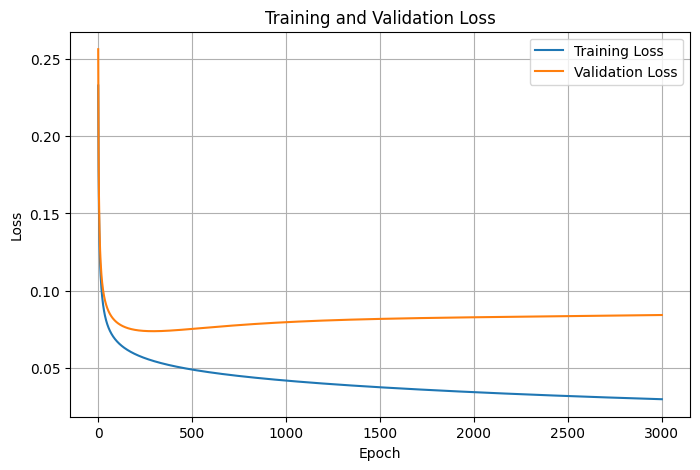

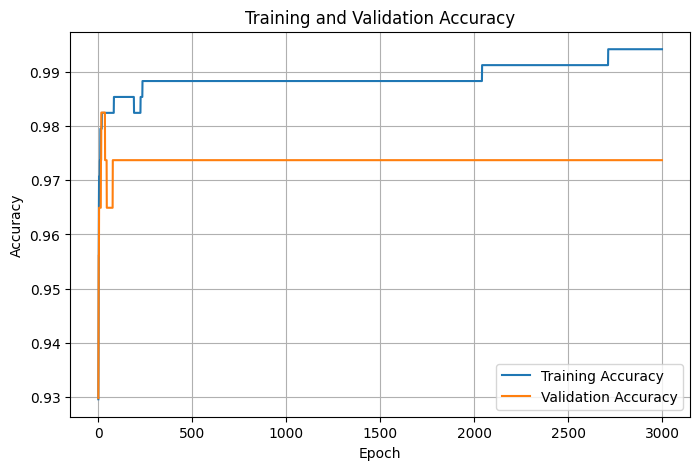

In [36]:
import matplotlib.pyplot as plt
best_results = results[best_lambda]
epochs_range = range(1, 3001)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, best_results["train_losses"], label="Training Loss")
plt.plot(epochs_range, best_results["val_losses"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(epochs_range, best_results["train_accs"], label="Training Accuracy")
plt.plot(epochs_range, best_results["val_accs"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [37]:
learning_rates = [0.01, 0.1, 1, 5, 20]
lr_results = {}

for lr in learning_rates:
    w, train_losses, val_losses, train_accs, val_accs = train_logistic(
        X_train, y_train,
        X_val, y_val,
        lam=0.01,
        learning_rate=lr,
        epochs=1000)

    lr_results[lr] = train_losses[-1]

    print("Learning Rate:", lr)
    print("Final Training Loss:", train_losses[-1])

Learning Rate: 0.01
Final Training Loss: 0.11628901770966023
Learning Rate: 0.1
Final Training Loss: 0.09831148320292545
Learning Rate: 1
Final Training Loss: 0.09811173825937314
Learning Rate: 5
Final Training Loss: 0.09811173825907171
Learning Rate: 20
Final Training Loss: 0.15782300657680046


#13-Separability:

In [38]:
w_sep = np.zeros(X_train.shape[1])
weight_norms = []
train_losses = []

for epoch in range(20000):
    grad = logistic_gradient(X_train, y_train, w_sep, lam=0)
    w_sep = w_sep - 0.5 * grad
    weight_norms.append(np.linalg.norm(w_sep[1:]))
    train_losses.append(logistic_loss(X_train, y_train, w_sep, lam=0))

print("Final Weight Norm:", weight_norms[-1])
print("Final Training Loss:", train_losses[-1])


Final Weight Norm: 19.07910409109684
Final Training Loss: 0.011458238949846756


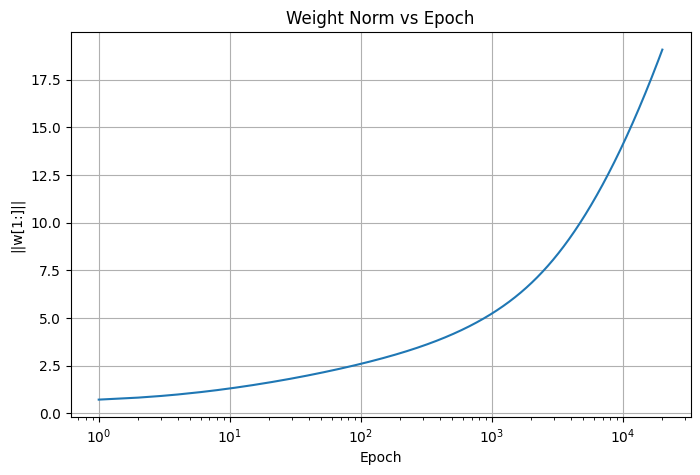

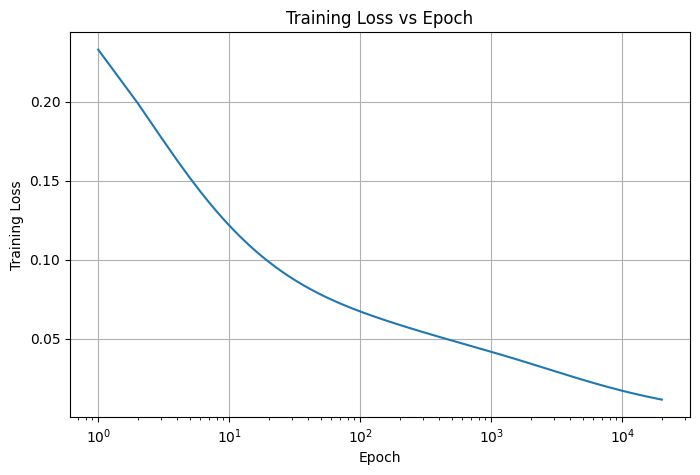

In [39]:
epochs_range = np.arange(1, 20001)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, weight_norms)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("||w[1:]||")
plt.title("Weight Norm vs Epoch")
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epoch")
plt.grid()
plt.show()

#14-Off-the-shelf comparison:


In [40]:
from sklearn.linear_model import LogisticRegression
sklearn_results = {}

for lam in lambdas:
    if lam == 0:
        model = LogisticRegression(
            penalty=None,
            max_iter=100000)
    else:
        C = 1 / (lam * len(y_train))
        model = LogisticRegression(
            C=C,
            max_iter=100000)

    model.fit(X_train[:, 1:], y_train)

    train_acc = model.score(X_train[:, 1:], y_train)
    val_acc = model.score(X_val[:, 1:], y_val)
    test_acc = model.score(X_test[:, 1:], y_test)

    sklearn_results[lam] = model

    print(f"Lambda = {lam}")
    print(f"C = {'None' if lam == 0 else C}")
    print(f"Train Accuracy = {train_acc:.4f}")
    print(f"Validation Accuracy = {val_acc:.4f}")
    print(f"Test Accuracy = {test_acc:.4f}")
    print()

Lambda = 0
C = None
Train Accuracy = 1.0000
Validation Accuracy = 0.9649
Test Accuracy = 0.9649

Lambda = 0.001
C = 2.9325513196480935
Train Accuracy = 0.9883
Validation Accuracy = 0.9737
Test Accuracy = 0.9737

Lambda = 0.01
C = 0.29325513196480935
Train Accuracy = 0.9853
Validation Accuracy = 0.9737
Test Accuracy = 0.9825

Lambda = 0.1
C = 0.029325513196480937
Train Accuracy = 0.9736
Validation Accuracy = 0.9737
Test Accuracy = 0.9737

Lambda = 1
C = 0.002932551319648094
Train Accuracy = 0.9384
Validation Accuracy = 0.9561
Test Accuracy = 0.9211



In [41]:
lam = 0.01
model = LogisticRegression(
    C=1 / (lam * len(y_train)),
    tol=1e-12,
    max_iter=100000)

model.fit(X_train[:, 1:], y_train)
w_sklearn = np.concatenate([model.intercept_, model.coef_.ravel()])
w_ours = results[lam]["w"]

relative_error = np.linalg.norm(w_ours - w_sklearn) / np.linalg.norm(w_sklearn)
pred_ours = (sigmoid(X_test @ w_ours) >= 0.5).astype(int)
pred_sklearn = model.predict(X_test[:, 1:])

print("Our weights:", w_ours[:5])
print("Sklearn weights:", w_sklearn[:5])
print("Relative Error:", relative_error)
print("Predictions Agree:", np.array_equal(pred_ours, pred_sklearn))

Our weights: [-0.42381639  0.45272781  0.4263065   0.43913875  0.43804957]
Sklearn weights: [-0.42381669  0.45272814  0.42630667  0.43913901  0.43804956]
Relative Error: 5.389606856862711e-07
Predictions Agree: True


In [42]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
C_results = []

for C in C_values:
    model = LogisticRegression(C=C, max_iter=100000)
    model.fit(X_train[:, 1:], y_train)
    C_results.append([
        C,
        model.score(X_train[:, 1:], y_train),
        model.score(X_val[:, 1:], y_val),
        model.score(X_test[:, 1:], y_test)])

print("C\t\tTrain Acc\tVal Acc\t\tTest Acc")
for row in C_results:
    print(f"{row[0]}\t\t{row[1]:.4f}\t\t{row[2]:.4f}\t\t{row[3]:.4f}")

C		Train Acc	Val Acc		Test Acc
0.001		0.8798		0.9035		0.8684
0.01		0.9501		0.9649		0.9474
0.1		0.9795		0.9825		0.9825
1		0.9883		0.9737		0.9737
10		0.9971		0.9649		0.9649
100		1.0000		0.9561		0.9561
1000		1.0000		0.9474		0.9561


In [43]:
import time
C = 1 / (0.01 * len(y_train))
solvers = ["lbfgs", "liblinear", "saga"]
solver_results = {}

for solver in solvers:
    model = LogisticRegression(
        C=C,
        solver=solver,
        tol=1e-8,
        max_iter=100000)

    start = time.perf_counter()
    model.fit(X_train[:, 1:], y_train)
    elapsed = time.perf_counter() - start
    coefficients = np.concatenate([model.intercept_, model.coef_.ravel()])
    solver_results[solver] = coefficients

    print(f"Solver: {solver}")
    print("Iterations:", model.n_iter_[0])
    print("Time:", elapsed)
    print("First 5 coefficients:", coefficients[:5])
    print()

print("Coefficient differences from lbfgs:")

for solver in solvers:
    difference = np.linalg.norm(
        solver_results[solver] - solver_results["lbfgs"]
    )
    print(solver, ":", difference)

Solver: lbfgs
Iterations: 28
Time: 0.012696619999985614
First 5 coefficients: [-0.42381676  0.45272816  0.42630668  0.43913902  0.43804954]

Solver: liblinear
Iterations: 10
Time: 0.006383171999971182
First 5 coefficients: [-0.28790001  0.44114212  0.41979197  0.42895102  0.44979909]

Solver: saga
Iterations: 776
Time: 0.21893303000001652
First 5 coefficients: [-0.42381648  0.45272779  0.4263066   0.43913872  0.4380496 ]

Coefficient differences from lbfgs:
lbfgs : 0.0
liblinear : 0.16265262175249076
saga : 1.890306690142754e-06


#15-Evaluation beyond accuracy:

In [44]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
w_001 = results[0.01]["w"]

test_scores = sigmoid(X_test @ w_001)
test_pred_05 = (test_scores >= 0.5).astype(int)

cm_05 = confusion_matrix(y_test, test_pred_05)
precision_05 = precision_score(y_test, test_pred_05)
recall_05 = recall_score(y_test, test_pred_05)
f1_05 = f1_score(y_test, test_pred_05)

print("Confusion Matrix:")
print(cm_05)
print("Precision:", precision_05)
print("Recall:", recall_05)
print("F1 Score:", f1_05)

Confusion Matrix:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1 Score: 0.975609756097561


AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
Absolute Difference: 1.1102230246251565e-16


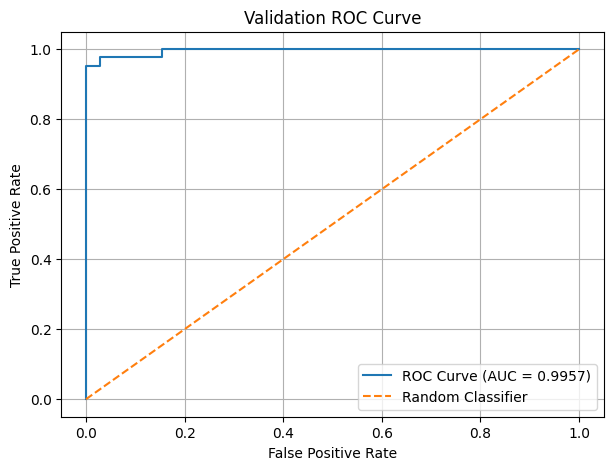

In [45]:
from sklearn.metrics import roc_auc_score
val_scores = sigmoid(X_val @ w_001)

sorted_indices = np.argsort(-val_scores)
sorted_scores = val_scores[sorted_indices]
sorted_y = y_val[sorted_indices]

cum_tp = np.cumsum(sorted_y)
cum_fp = np.cumsum(1 - sorted_y)

distinct_indices = np.where(np.diff(sorted_scores) != 0)[0]
distinct_indices = np.append(distinct_indices, len(sorted_scores) - 1)

tp = cum_tp[distinct_indices]
fp = cum_fp[distinct_indices]

tpr = np.concatenate([[0], tp / np.sum(y_val)])
fpr = np.concatenate([[0], fp / np.sum(1 - y_val)])

auc_scratch = np.trapezoid(tpr, fpr)
auc_sklearn = roc_auc_score(y_val, val_scores)

print("AUC from scratch:", auc_scratch)
print("AUC from sklearn:", auc_sklearn)
print("Absolute Difference:", abs(auc_scratch - auc_sklearn))

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_scratch:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [46]:
tau = np.min(val_scores[y_val == 1])

val_pred_tau = (val_scores >= tau).astype(int)
val_recall_tau = recall_score(y_val, val_pred_tau)

test_pred_tau = (test_scores >= tau).astype(int)

cm_tau = confusion_matrix(y_test, test_pred_tau)
precision_tau = precision_score(y_test, test_pred_tau, zero_division=0)
recall_tau = recall_score(y_test, test_pred_tau)

print("Selected Threshold:", tau)
print("Validation Recall:", val_recall_tau)
print("\nTest Confusion Matrix at tau:")
print(cm_tau)
print("Test Precision:", precision_tau)
print("Test Recall:", recall_tau)

Selected Threshold: 0.14602532493304418
Validation Recall: 1.0

Test Confusion Matrix at tau:
[[66  6]
 [ 1 41]]
Test Precision: 0.8723404255319149
Test Recall: 0.9761904761904762


#16-The boundary in original coordinates:

In [47]:
feature_indices = [0, 1]

X_train_raw = splits["Breast Cancer"][0][:, feature_indices]
X_val_raw = splits["Breast Cancer"][1][:, feature_indices]
X_test_raw = splits["Breast Cancer"][2][:, feature_indices]

scaler_2 = Standardizer()
scaler_2.fit(X_train_raw)

X_train_2 = add_bias(scaler_2.transform(X_train_raw))
X_val_2 = add_bias(scaler_2.transform(X_val_raw))
X_test_2 = add_bias(scaler_2.transform(X_test_raw))

print("Train shape:", X_train_2.shape)
print("Mean:", scaler_2.mean)
print("Std:", scaler_2.std)

Train shape: (341, 3)
Mean: [14.16341935 19.42876833]
Std: [3.5940381  4.35476066]


In [48]:
w_2 = np.zeros(X_train_2.shape[1])
for epoch in range(5000):
    grad = logistic_gradient(X_train_2, y_train, w_2, lam=0)
    w_2 = w_2 - 0.5 * grad
print("Weights:", w_2)

Weights: [-0.7271724   3.65679417  1.00987153]


In [49]:
w_orig = np.zeros_like(w_2)
w_orig[1:] = w_2[1:] / scaler_2.std
w_orig[0] = w_2[0] - np.sum(
    w_2[1:] * scaler_2.mean / scaler_2.std)
print("Original weights:", w_orig)

Original weights: [-19.64344417   1.01746116   0.23190058]


In [50]:
scores_standardized = X_test_2 @ w_2
scores_original = add_bias(X_test_raw) @ w_orig
max_difference = np.max(
    np.abs(scores_standardized - scores_original))
print("Maximum difference:", max_difference)
print("Verification passed:", max_difference < 1e-9)

Maximum difference: 3.552713678800501e-15
Verification passed: True


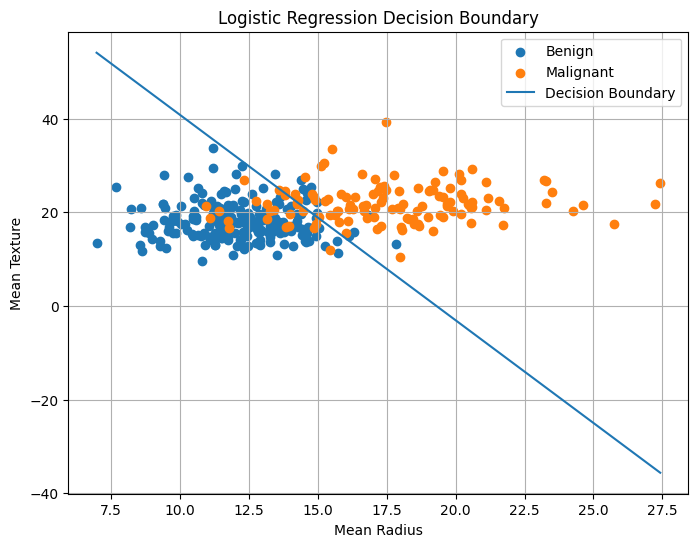

In [51]:
x_values = np.linspace(
    X_train_raw[:, 0].min(),
    X_train_raw[:, 0].max(),
    100)

y_values = -(w_orig[0] + w_orig[1] * x_values) / w_orig[2]
plt.figure(figsize=(8, 6))
plt.scatter(
    X_train_raw[y_train == 0, 0],
    X_train_raw[y_train == 0, 1],
    label="Benign")

plt.scatter(
    X_train_raw[y_train == 1, 0],
    X_train_raw[y_train == 1, 1],
    label="Malignant")

plt.plot(x_values, y_values, label="Decision Boundary")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

# **Part D : Softmax Classifier:**

In [52]:

# Retrieve the PROCESSED Digits dataset
X_train_final, X_val_final, X_test_final, y_train, y_val, y_test = processed_data["Digits"]

def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_scores = np.exp(S_shifted)
    P = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    return P

# 2. Stable cross-entropy loss + regularization
def softmax_loss(W, X, y, lam=0.0):
    N = X.shape[0]
    S = X @ W
    m = np.max(S, axis=1, keepdims=True)
    log_sum_exp = ( m[:, 0]+ np.log(np.sum(np.exp(S - m), axis=1)))
    correct_scores = S[np.arange(N), y]
    data_loss = np.mean(log_sum_exp - correct_scores)
    reg_loss = (lam / 2) * np.sum(W[1:, :] ** 2)
    return data_loss + reg_loss

 # 3. Gradient
def softmax_grad(W, X, y, lam=0.0):
    N = X.shape[0]
    S = X @ W
    P = softmax(S)
    Y = np.eye(W.shape[1])[y]
    grad = (X.T @ (P - Y)) / N
    grad[1:, :] += lam * W[1:, :]
    return grad
#4.check w=0
W_zero = np.zeros((65, 10))
loss_zero = softmax_loss(
    W_zero,
    X_train_final,
    y_train,
    lam=0.1
)
print("Loss at W=0:", loss_zero)
assert np.isclose(loss_zero, np.log(10))



Loss at W=0: 2.3025850929940463


In [53]:
def predict_softmax(W, X):
    scores = X @ W
    probabilities = softmax(scores)
    return np.argmax(probabilities, axis=1)

def calculate_accuracy(W, X, y):
    predictions = predict_softmax(W, X)
    return np.mean(predictions == y)

def train_softmax(X_train, y_train, X_val, y_val,
                  eta, lam=0.0, epochs=100, batch_size=64):

    N = X_train.shape[0]
    K = 10  #10 possible classes
    W = np.zeros((X_train.shape[1], K))
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [] }
        #Creates a random permutation of the image indices.
    rng = np.random.default_rng(42)
    for epoch in range(epochs):
        indices = rng.permutation(N)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Divide into mini-batches
        for start in range(0, N, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Calculate gradient
            grad = softmax_grad(W, X_batch, y_batch, lam)
            # Update weights
            W = W - eta * grad
        # Evaluate after each epoch
        history["train_loss"].append(
            softmax_loss(W, X_train, y_train, lam)
        )
        history["val_loss"].append(
            softmax_loss(W, X_val, y_val, lam)
        )
        history["train_acc"].append(
            calculate_accuracy(W, X_train, y_train)
        )
        history["val_acc"].append(
            calculate_accuracy(W, X_val, y_val)
        )

    return W, history
results = {}
learning_rates = [0.01, 0.1, 0.5, 1.0]
for n in learning_rates:
    W, history = train_softmax(
        X_train_final, y_train,
        X_val_final, y_val,
        eta=n,
        lam=0.0,
        epochs=100,
        batch_size=64 )
    results[n] = {
        "W": W,
        "history": history
    }
    print("Finished eta =", n)

Finished eta = 0.01
Finished eta = 0.1
Finished eta = 0.5
Finished eta = 1.0


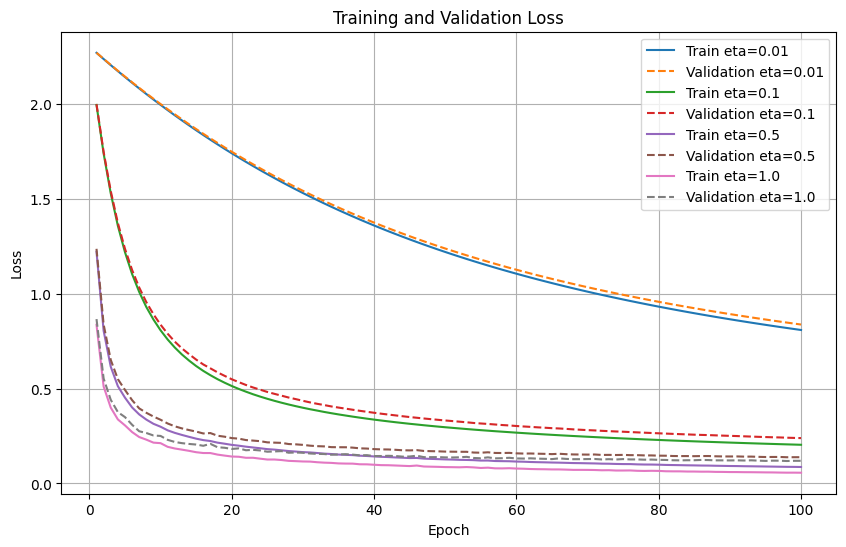

In [54]:
#Plot the losses
import matplotlib.pyplot as plt

epochs = range(1, 101)

plt.figure(figsize=(10, 6))

for n in learning_rates:
    history = results[n]["history"]

    plt.plot(
        epochs,
        history["train_loss"],
        label=f"Train eta={n}"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"Validation eta={n}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

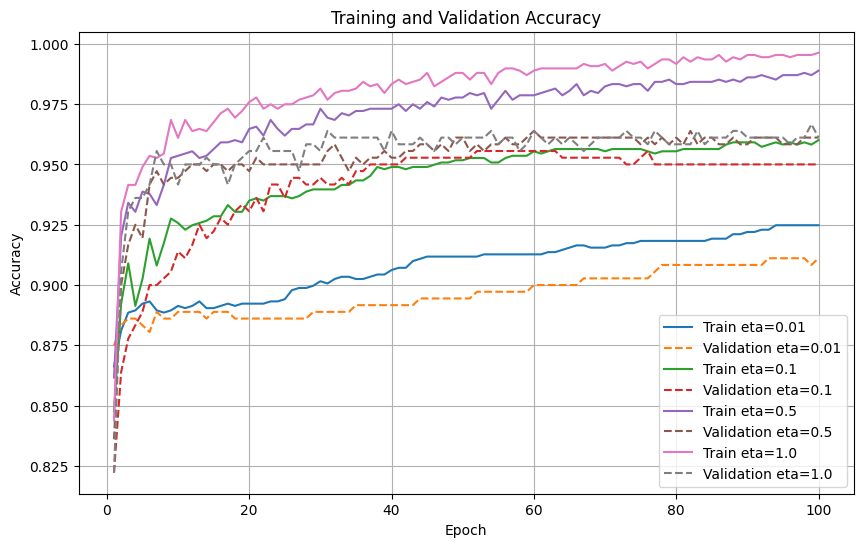

In [55]:
#plot accurancy
plt.figure(figsize=(10, 6))

for n in learning_rates:
    history = results[n]["history"]

    plt.plot(
        epochs,
        history["train_acc"],
        label=f"Train eta={n}"
    )

    plt.plot(
        epochs,
        history["val_acc"],
        linestyle="--",
        label=f"Validation eta={n}"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [56]:
#result table
import pandas as pd

rows = []

for n in learning_rates:
    history = results[n]["history"]

    rows.append({
        "Learning Rate": n,
        "Final Train Loss": history["train_loss"][-1],
        "Final Val Loss": history["val_loss"][-1],
        "Final Train Accuracy": history["train_acc"][-1],
        "Final Val Accuracy": history["val_acc"][-1]
    })

results_table = pd.DataFrame(rows)

print(results_table)
best_eta = results_table.loc[
    results_table["Final Val Loss"].idxmin(),
    "Learning Rate"
]

print("Best learning rate:", best_eta)

   Learning Rate  Final Train Loss  Final Val Loss  Final Train Accuracy  \
0           0.01          0.808641        0.837388              0.924791   
1           0.10          0.203817        0.238951              0.960074   
2           0.50          0.086785        0.138329              0.988858   
3           1.00          0.056569        0.119327              0.996286   

   Final Val Accuracy  
0            0.911111  
1            0.950000  
2            0.961111  
3            0.961111  
Best learning rate: 1.0


In [57]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]

lambda_results = {}

for lam in lambdas:

    W, history = train_softmax(
        X_train_final, y_train,
        X_val_final, y_val,
        eta=best_eta,
        lam=lam,
        epochs=100,
        batch_size=64
    )

    lambda_results[lam] = {
        "W": W,
        "history": history
    }

    print("Finished lambda =", lam)
    rows = []

for lam in lambdas:

    history = lambda_results[lam]["history"]

    rows.append({
        "Lambda": lam,
        "Train Loss": history["train_loss"][-1],
        "Validation Loss": history["val_loss"][-1],
        "Train Accuracy": history["train_acc"][-1],
        "Validation Accuracy": history["val_acc"][-1]
    })

lambda_table = pd.DataFrame(rows)

print(lambda_table)
best_lambda = lambda_table.sort_values(
    by=["Validation Accuracy", "Lambda"],
    ascending=[False, False]
).iloc[0]["Lambda"]

print("Best lambda:", best_lambda)
best_W = lambda_results[best_lambda]["W"]

test_accuracy = calculate_accuracy(
    best_W,
    X_test_final,
    y_test
)

print("Test Accuracy:", test_accuracy)

Finished lambda = 0
Finished lambda = 0.0001
Finished lambda = 0.001
Finished lambda = 0.01
Finished lambda = 0.1
   Lambda  Train Loss  Validation Loss  Train Accuracy  Validation Accuracy
0  0.0000    0.056569         0.119327        0.996286             0.961111
1  0.0001    0.091589         0.150828        0.996286             0.963889
2  0.0010    0.257953         0.304194        0.980501             0.966667
3  0.0100    0.746276         0.785556        0.938719             0.927778
4  0.1000    1.775121         1.803547        0.641597             0.633333
Best lambda: 0.001
Test Accuracy: 0.9527777777777777


In [58]:
#19.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

N_train = X_train_final.shape[0]

# Remove bias column for sklearn.
# sklearn adds its own automatically.
X_train_sklearn = X_train_final[:, 1:]
X_val_sklearn = X_val_final[:, 1:]
X_test_sklearn = X_test_final[:, 1:]

sklearn_lambda_results = {}

for lam in lambdas:

    if lam == 0:
        C = np.inf
    else:
        C = 1 / (lam * N_train)

    model = LogisticRegression(
        C=C,
        max_iter=10000,
        solver="lbfgs"
    )

    model.fit(X_train_sklearn, y_train)

    val_pred = model.predict(X_val_sklearn)
    test_pred = model.predict(X_test_sklearn)

    sklearn_lambda_results[lam] = {
        "model": model,
        "val_acc": accuracy_score(y_val, val_pred),
        "test_acc": accuracy_score(y_test, test_pred),
        "test_pred": test_pred
    }

    print("Finished lambda =", lam, "C =", C)
    rows = []

for lam in lambdas:

    own_history = lambda_results[lam]["history"]

    rows.append({
        "Lambda": lam,

        "Own Val Accuracy":
            own_history["val_acc"][-1],

        "Sklearn Val Accuracy":
            sklearn_lambda_results[lam]["val_acc"],

        "Own Test Accuracy":
            accuracy_score(
                y_test,
                predict_softmax(
                    lambda_results[lam]["W"],
                    X_test_final
                )
            ),

        "Sklearn Test Accuracy":
            sklearn_lambda_results[lam]["test_acc"]
    })

comparison_table = pd.DataFrame(rows)

print(comparison_table)

Finished lambda = 0 C = inf
Finished lambda = 0.0001 C = 9.285051067780872
Finished lambda = 0.001 C = 0.9285051067780873
Finished lambda = 0.01 C = 0.09285051067780874
Finished lambda = 0.1 C = 0.009285051067780872
   Lambda  Own Val Accuracy  Sklearn Val Accuracy  Own Test Accuracy  \
0  0.0000          0.961111              0.955556           0.958333   
1  0.0001          0.963889              0.975000           0.958333   
2  0.0010          0.966667              0.972222           0.952778   
3  0.0100          0.927778              0.947222           0.925000   
4  0.1000          0.633333              0.902778           0.619444   

   Sklearn Test Accuracy  
0               0.955556  
1               0.961111  
2               0.955556  
3               0.933333  
4               0.886111  


In [59]:
# direct c values
C_values = [0.1, 1, 10, 100]

C_results = {}

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=10000,
        solver="lbfgs"
    )

    model.fit(X_train_sklearn, y_train)

    val_pred = model.predict(X_val_sklearn)
    test_pred = model.predict(X_test_sklearn)

    C_results[C] = {
        "model": model,
        "val_acc": accuracy_score(y_val, val_pred),
        "test_acc": accuracy_score(y_test, test_pred)
    }

C_table = pd.DataFrame([
    {
        "C": C,
        "Validation Accuracy": C_results[C]["val_acc"],
        "Test Accuracy": C_results[C]["test_acc"]
    }
    for C in C_values
])

print(C_table)
#Compare test predictions for lambda*
own_test_pred = predict_softmax(best_W, X_test_final)

sklearn_test_pred = sklearn_lambda_results[
    best_lambda
]["test_pred"]

agreement = np.mean(
    own_test_pred == sklearn_test_pred
)

print("Prediction agreement:", agreement)
print("Agreement percentage:", agreement * 100, "%")

assert agreement >= 0.97

       C  Validation Accuracy  Test Accuracy
0    0.1             0.950000       0.938889
1    1.0             0.972222       0.955556
2   10.0             0.963889       0.955556
3  100.0             0.961111       0.955556
Prediction agreement: 0.9916666666666667
Agreement percentage: 99.16666666666667 %


y_test shape: (360,)
y_pred shape: (360,)


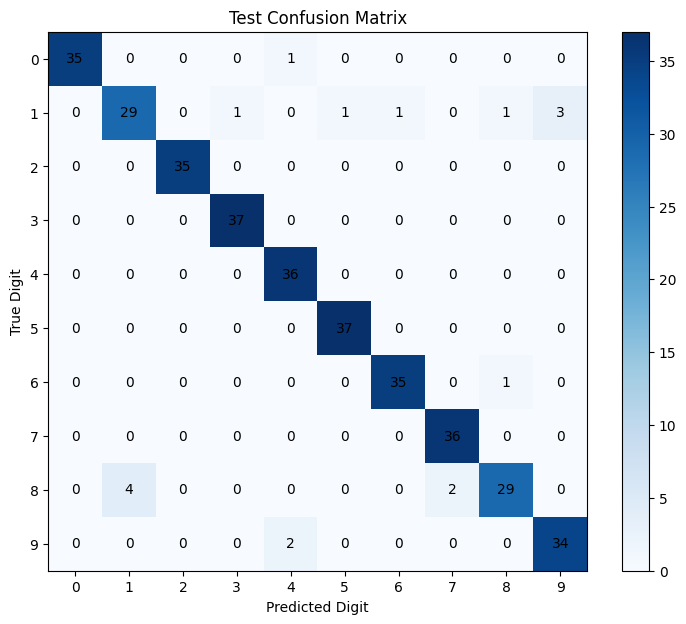

   precision    recall  f1-score  support
0   1.000000  0.972222  0.985915     36.0
1   0.878788  0.805556  0.840580     36.0
2   1.000000  1.000000  1.000000     35.0
3   0.973684  1.000000  0.986667     37.0
4   0.923077  1.000000  0.960000     36.0
5   0.973684  1.000000  0.986667     37.0
6   0.972222  0.972222  0.972222     36.0
7   0.947368  1.000000  0.972973     36.0
8   0.935484  0.828571  0.878788     35.0
9   0.918919  0.944444  0.931507     36.0
    True Digit  Predicted Digit  Number of Errors
73           8                1                 4
17           1                9                 3
79           8                7                 2


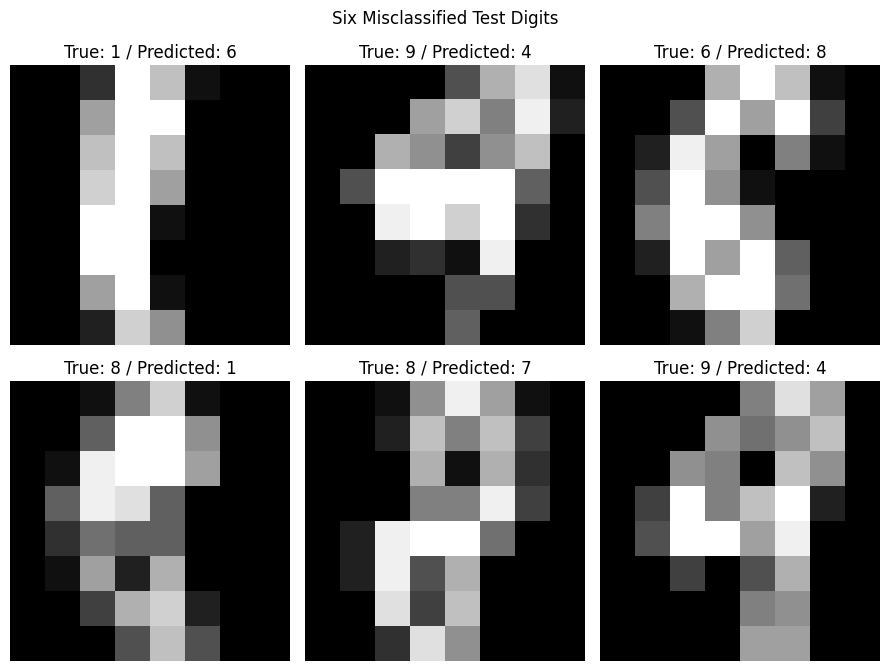

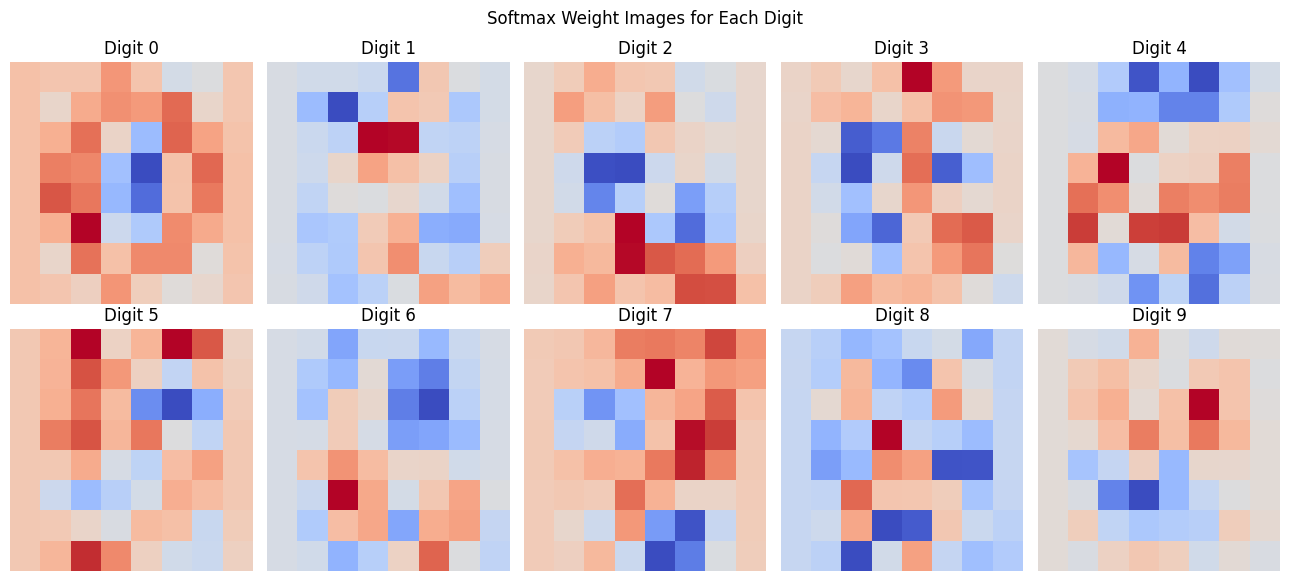

In [60]:
#error analysis
# Generate predictions for the test set
scores = X_test_final @ best_W

probabilities = softmax(scores)

y_pred = np.argmax(probabilities, axis=1)

print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap="Blues")

plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.title("Test Confusion Matrix")

# Display the numbers inside the cells
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center")

plt.show()
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(10),
    output_dict=True,
    zero_division=0
)

metrics_table = pd.DataFrame(report).T

print(metrics_table.loc[
    [str(i) for i in range(10)],
    ["precision", "recall", "f1-score", "support"]
])
#Find the three most confused pairs
cm_no_diagonal = cm.copy()

np.fill_diagonal(cm_no_diagonal, 0)

pairs = []

for i in range(10):
    for j in range(10):

        if i != j:
            pairs.append({
                "True Digit": i,
                "Predicted Digit": j,
                "Number of Errors": cm_no_diagonal[i, j]
            })

pairs_table = pd.DataFrame(pairs)

top_three = pairs_table.sort_values(
    by="Number of Errors",
    ascending=False
).head(3)

print(top_three)
#Display six misclassified digits
# Find incorrect predictions
wrong_indices = np.where(y_test != y_pred)[0]

# Select six examples
selected_indices = wrong_indices[:6]

fig, axes = plt.subplots(2, 3, figsize=(9, 7))

for ax, idx in zip(axes.flat, selected_indices):

    # Remove bias column and reshape
    image = X_test_final[idx, 1:].reshape(8, 8)

    ax.imshow(image, cmap="gray")

    ax.set_title(
        f"True: {y_test[idx]} / Predicted: {y_pred[idx]}"
    )

    ax.axis("off")

plt.suptitle("Six Misclassified Test Digits")
plt.tight_layout()
plt.show()
#Visualize the ten class weight images
# Remove bias row
class_weights = best_W[1:, :]

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for digit, ax in enumerate(axes.flat):

    weight_image = class_weights[:, digit].reshape(8, 8)

    im = ax.imshow(weight_image, cmap="coolwarm")

    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.suptitle("Softmax Weight Images for Each Digit")

plt.tight_layout()
plt.show()

Digit 1 is the hardest because it has the lowest F1-score (0.841).
Digit 8 is the second hardest (0.879).
Digit 9 is the third hardest (0.932).

The model sometimes recognizes an 8 as a 1.
It sometimes recognizes a 1 as a 9.
It sometimes recognizes an 8 as a 7.

A linear model on raw pixels uses a weighted sum of individual pixel values and cannot effectively capture complex shapes, curves, rotations, or spatial relationships between pixels.

In [61]:
#Softmax with K = 2 is Logistic Regression
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load breast cancer dataset
X_train_cancer, X_val_cancer, X_test_cancer, y_train_cancer, y_val_cancer, y_test_cancer = processed_data["Breast Cancer"]

# Two classes: 0 and 1
# 31 features including bias

np.random.seed(42)
W = np.random.randn(31, 2)
# 1. Calculate Softmax probabilities
scores = X_test_cancer @ W
P_softmax = softmax(scores)
# Probability of class 1
P_softmax_class1 = P_softmax[:, 1]

# 2. Calculate Sigmoid probabilities
w0 = W[:, 0]
w1 = W[:, 1]
w_difference = w1 - w0
z = X_test_cancer @ w_difference
P_sigmoid = 1 / (1 + np.exp(-z))

# 3. Compare the results
max_difference = np.max(
    np.abs(P_softmax_class1 - P_sigmoid)
)
print("Maximum difference:", max_difference)
assert np.allclose(
    P_softmax_class1,
    P_sigmoid,
    atol=1e-12
)
print("Softmax and Sigmoid are equivalent!")

Maximum difference: 7.216449660063518e-16
Softmax and Sigmoid are equivalent!


In [62]:
#two Iris features: petal length and petal width.
X_train_iris, X_val_iris, X_test_iris, y_train_iris, y_val_iris, y_test_iris = splits["Iris"]

# prepare the data
X_train_iris = X_train_iris[:, 2:4]
X_val_iris = X_val_iris[:, 2:4]
X_test_iris = X_test_iris[:, 2:4]
print(X_train_iris.shape)
iris_scaler = Standardizer()
iris_scaler.fit(X_train_iris)
X_train_iris = iris_scaler.transform(X_train_iris)
X_val_iris = iris_scaler.transform(X_val_iris)
X_test_iris = iris_scaler.transform(X_test_iris)
X_train_iris_bias = add_bias(X_train_iris)
X_val_iris_bias = add_bias(X_val_iris)
X_test_iris_bias = add_bias(X_test_iris)
print("Training:", X_train_iris_bias.shape)
print("Validation:", X_val_iris_bias.shape)
print("Testing:", X_test_iris_bias.shape)


(90, 2)
Training: (90, 3)
Validation: (30, 3)
Testing: (30, 3)


(3, 3)
(3, 3)


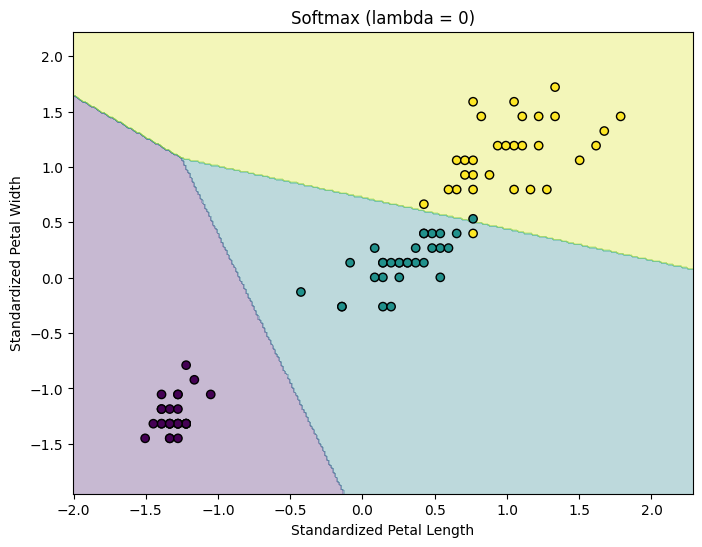

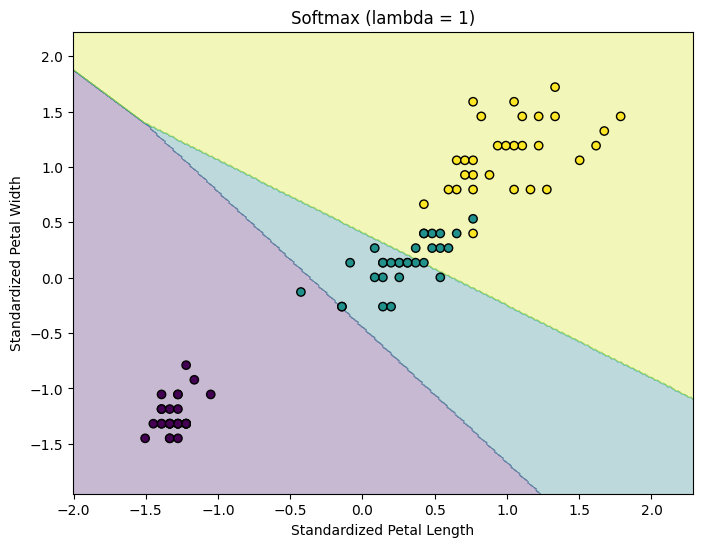

In [63]:
#Train our Softmax classifier
def train_softmax_full_batch(X, y, eta=0.5, lam=0.0, epochs=2000):
    N = X.shape[0]
    K = len(np.unique(y))
    W = np.zeros((X.shape[1], K))
    for epoch in range(epochs):
        grad = softmax_grad(W, X, y, lam)
        W = W - eta * grad

    return W
# Train lambda = 0
W_iris_0 = train_softmax_full_batch(
    X_train_iris_bias,
    y_train_iris,
    eta=0.5,
    lam=0,
    epochs=2000
)
# Train lambda = 1
W_iris_1 = train_softmax_full_batch(
    X_train_iris_bias,
    y_train_iris,
    eta=0.5,
    lam=1,
    epochs=2000
)
print(W_iris_0.shape)
print(W_iris_1.shape)


################################################################################################plot
import matplotlib.pyplot as plt

def plot_decision_regions(X, y, W, title):

    # Create mesh grid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    # Combine grid points
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Add bias
    grid_bias = add_bias(grid)

    # Predict classes
    scores = grid_bias @ W
    probabilities = softmax(scores)
    Z = np.argmax(probabilities, axis=1)

    Z = Z.reshape(xx.shape)

    # Plot
    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        edgecolors="black",
        cmap="viridis"
    )

    plt.xlabel("Standardized Petal Length")
    plt.ylabel("Standardized Petal Width")
    plt.title(title)
    plt.show()

    ###############call
plot_decision_regions(
   X_train_iris, y_train_iris, W_iris_0,
  "Softmax (lambda = 0)"
)

plot_decision_regions(
    X_train_iris, y_train_iris, W_iris_1,
    "Softmax (lambda = 1)"
)

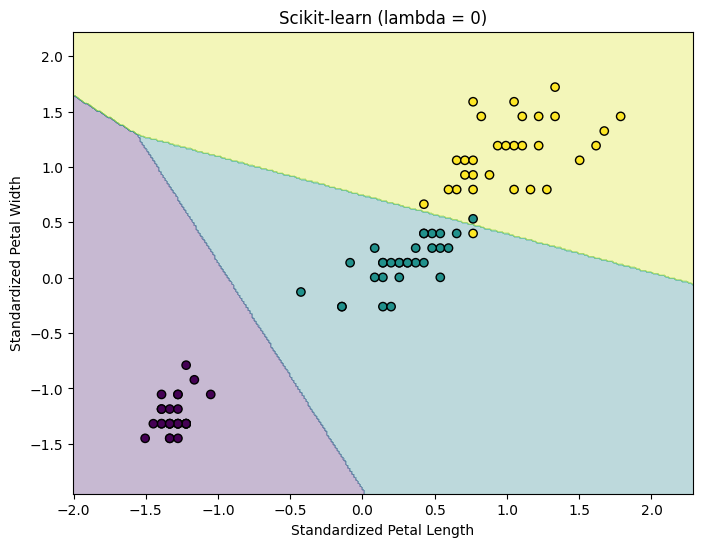

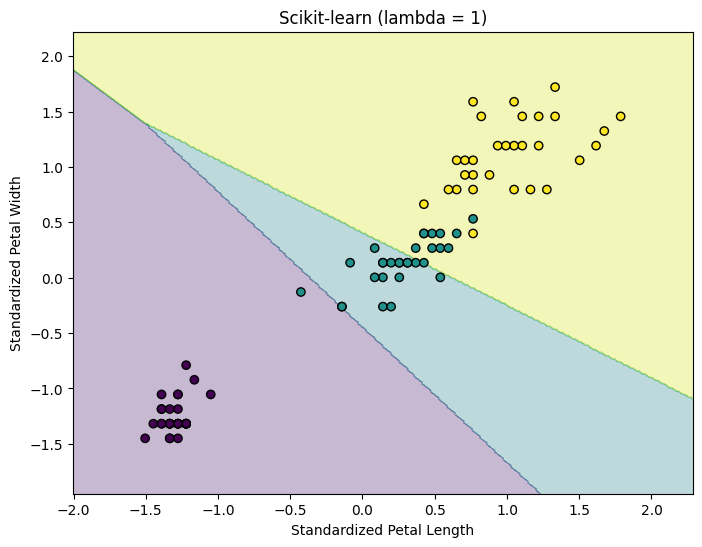

In [64]:
#skitlearn
from sklearn.linear_model import LogisticRegression

model_0 = LogisticRegression(
    C=1e12,
    max_iter=10000,
    solver="lbfgs"
)

model_1 = LogisticRegression(
    C=1/90,
    max_iter=10000,
    solver="lbfgs"
)

model_0.fit(X_train_iris, y_train_iris)
model_1.fit(X_train_iris, y_train_iris)
####################################################################plot
def plot_sklearn_regions(X, y, model, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        edgecolors="black",
        cmap="viridis"
    )

    plt.xlabel("Standardized Petal Length")
    plt.ylabel("Standardized Petal Width")
    plt.title(title)
    plt.show()
# Call the function
plot_sklearn_regions(
    X_train_iris, y_train_iris, model_0,
    "Scikit-learn (lambda = 0)"
)

plot_sklearn_regions(
    X_train_iris, y_train_iris, model_1,
    "Scikit-learn (lambda = 1)"
)

# **Part E: SVM:**

# Part E — Support Vector Machines
## Task 23 — Linear SVM from scratch (Breast Cancer, standardized, labels ±1, λ = 0.01)


### Model and subgradient
$f(x)=w\cdot x+b,\; y_i\in\{-1,+1\}$,

$$J(w,b)=\frac{\lambda}{2}\|w\|^2+\frac1N\sum_i \max(0,\,1-y_i f(x_i))$$

The hinge is not differentiable at $y_if(x_i)=1$, so we use a subgradient. With $V=\{i:\;y_if(x_i)<1\}$:

$$\frac{\partial J}{\partial w}=\lambda w-\frac1N\sum_{i\in V}y_ix_i,\qquad \frac{\partial J}{\partial b}=-\frac1N\sum_{i\in V}y_i$$

The bias $b$ is **not** regularized. Only samples that touch or violate the margin contribute to the gradient.

In [66]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC   # for later comparison
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Breast Cancer from the shared pipeline. The first column is the bias column of ones;
# the SVM keeps b separate, so it is dropped here. Labels are converted to -1 / +1.
Xc_tr, Xc_va, Xc_te, yc_tr, yc_va, yc_te = processed_data["Breast Cancer"]
Xc_tr, Xc_va, Xc_te = Xc_tr[:, 1:], Xc_va[:, 1:], Xc_te[:, 1:]
yc_tr, yc_va, yc_te = 2 * yc_tr - 1, 2 * yc_va - 1, 2 * yc_te - 1
n_train = len(yc_tr)


def svm_objective(w, b, X, y, lam):
    hinge = np.maximum(0, 1 - y * (X @ w + b))
    return 0.5 * lam * (w @ w) + hinge.mean()


def svm_subgradient(w, b, X, y, lam):
    violating = y * (X @ w + b) < 1
    grad_w = lam * w - X[violating].T @ y[violating] / len(y)
    grad_b = -y[violating].sum() / len(y)
    return grad_w, grad_b


def svm_predict(w, b, X):
    return np.where(X @ w + b >= 0, 1, -1)


def train_svm(X, y, X_val, y_val, lam, n_iter, step):
    # full-batch subgradient descent from w = 0, b = 0
    w, b = np.zeros(X.shape[1]), 0.0
    objectives, val_accuracies = [], []
    for t in range(1, n_iter + 1):
        grad_w, grad_b = svm_subgradient(w, b, X, y, lam)
        eta = step(t)
        w, b = w - eta * grad_w, b - eta * grad_b
        objectives.append(svm_objective(w, b, X, y, lam))
        val_accuracies.append(accuracy(y_val, svm_predict(w, b, X_val)))
    return w, b, np.array(objectives), np.array(val_accuracies)


# Gradient check (Part A grad_check) with theta = [w, b], eps = 1e-6
lam = 0.01
f = lambda theta: svm_objective(theta[:-1], theta[-1], Xc_tr, yc_tr, lam)
g = lambda theta: np.append(*svm_subgradient(theta[:-1], theta[-1], Xc_tr, yc_tr, lam))

rng = np.random.default_rng(42)
theta0 = rng.normal(0, 0.1, Xc_tr.shape[1] + 1)
error = grad_check(f, g, theta0, eps=1e-6)
print(f"Relative error: {error:.2e}  ->", "passed" if error < 1e-5 else "FAILED")

Relative error: 1.59e-10  -> passed


### Results

In [67]:
schedules = {
    "constant η = 0.1": lambda t: 0.1,
    "constant η = 1.0": lambda t: 1.0,
    "η_t = 1/√t":       lambda t: 1 / np.sqrt(t),
}
runs = {name: train_svm(Xc_tr, yc_tr, Xc_va, yc_va, lam, 3000, step) for name, step in schedules.items()}

summary = pd.DataFrame({
    name: {"final J": objs[-1], "std of J (last 200 it.)": objs[-200:].std(), "final val acc": accs[-1]}
    for name, (w, b, objs, accs) in runs.items()
}).T
display(summary)

,final J,std of J (last 200 it.),final val acc
constant η = 0.1,0.060544,0.000043,0.973684
constant η = 1.0,0.060961,0.000448,0.973684
η_t = 1/√t,0.060798,0.000011,0.973684


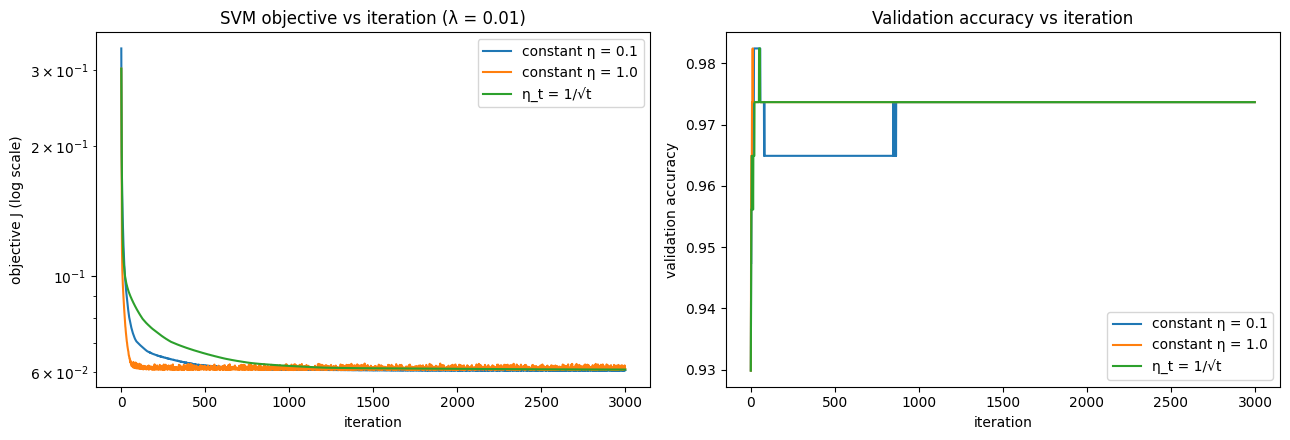

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (w, b, objs, accs) in runs.items():
    axes[0].plot(objs, label=name)
    axes[1].plot(accs, label=name)

axes[0].set_yscale("log")
axes[0].set(title="SVM objective vs iteration (λ = 0.01)", xlabel="iteration", ylabel="objective J (log scale)")
axes[1].set(title="Validation accuracy vs iteration", xlabel="iteration", ylabel="validation accuracy")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

## Task 24 — Comparison with scikit-learn

**Task.** Run 20,000 iterations with η_t = 1/√t and compare with `SVC(kernel="linear", C=1/(λ·N_train))`. Then sweep λ and compare with `SVC` and `LinearSVC(loss="hinge")`.

In [69]:
lambdas = [1e-4, 1e-3, 1e-2, 1e-1, 1]
fits = {}

for lam_i in lambdas:
    C = 1 / (lam_i * n_train)
    w, b, _, _ = train_svm(Xc_tr, yc_tr, Xc_va, yc_va, lam_i, 20000, lambda t: 1 / np.sqrt(t))
    fits[lam_i] = {
        "mine": (w, b),
        "SVC": SVC(kernel="linear", C=C).fit(Xc_tr, yc_tr),
        "LinearSVC": LinearSVC(loss="hinge", C=C, dual=True, tol=1e-8, max_iter=1_000_000, random_state=42).fit(Xc_tr, yc_tr),
    }

### Results (λ = 0.01)

In [70]:
w, b = fits[0.01]["mine"]
svc = fits[0.01]["SVC"]
w_sk, b_sk = svc.coef_.ravel(), svc.intercept_[0]

j_mine = svm_objective(w, b, Xc_tr, yc_tr, 0.01)
j_sk = svm_objective(w_sk, b_sk, Xc_tr, yc_tr, 0.01)
cosine = w @ w_sk / (np.linalg.norm(w) * np.linalg.norm(w_sk))
agreement = np.mean(svm_predict(w, b, Xc_te) == svc.predict(Xc_te))
n_sv_mine = int((yc_tr * (Xc_tr @ w + b) <= 1).sum())
n_sv_sk = int(svc.n_support_.sum())

display(pd.DataFrame([
    ["Objective J (relative gap)", f"{j_mine:.5f} vs {j_sk:.5f} ({abs(j_mine - j_sk) / j_sk:.1e})", abs(j_mine - j_sk) / j_sk < 1e-3],
    ["Cosine similarity of w", f"{cosine:.5f}", cosine >= 0.99],
    ["Test-prediction agreement", f"{agreement:.4f}", agreement >= 0.98],
    ["Margin width 2/||w||", f"{2 / np.linalg.norm(w):.4f} vs {2 / np.linalg.norm(w_sk):.4f}", True],
    ["#points with y·f(x) ≤ 1 vs n_support_", f"{n_sv_mine} vs {n_sv_sk}", abs(n_sv_mine - n_sv_sk) <= 5],
], columns=["Quantity (mine vs SVC)", "Value", "Within tolerance"]).set_index("Quantity (mine vs SVC)"))

,Value,Within tolerance
Quantity (mine vs SVC),,
Objective J (relative gap),0.06045 vs 0.06044 (2.0e-04),True
Cosine similarity of w,0.99969,True
Test-prediction agreement,1.0000,True
Margin width 2/||w||,1.1318 vs 1.1291,True
#points with y·f(x) ≤ 1 vs n_support_,28 vs 32,True


### Results (λ sweep)

In [71]:
def describe(model, w, b, lam, n_sv=None):
    # n_sv is given for SVC (n_support_); otherwise count the training points with y·f(x) <= 1
    if n_sv is None:
        n_sv = int((yc_tr * (Xc_tr @ w + b) <= 1).sum())
    return {"λ": lam, "C": f"{1 / (lam * n_train):.3g}", "model": model,
            "val acc": accuracy(yc_va, svm_predict(w, b, Xc_va)),
            "margin 2/||w||": 2 / np.linalg.norm(w), "#SV": n_sv,
            "objective J": svm_objective(w, b, Xc_tr, yc_tr, lam), "|b|": abs(b)}


rows = []
for lam_i, models in fits.items():
    w, b = models["mine"]
    rows.append(describe("mine", w, b, lam_i))
    svc = models["SVC"]
    rows.append(describe("SVC", svc.coef_.ravel(), svc.intercept_[0], lam_i, int(svc.n_support_.sum())))
    lsvc = models["LinearSVC"]
    rows.append(describe("LinearSVC", lsvc.coef_.ravel(), lsvc.intercept_[0], lam_i))

display(pd.DataFrame(rows).round(4).set_index(["λ", "C", "model"]))

val acc  margin 2/||w||  #SV  objective J     |b|
λ      C       model                                                       
0.0001 29.3    mine        0.9649          0.5923   15       0.0304  0.2756
               SVC         0.9474          0.1460   22       0.0094  1.3773
               LinearSVC   0.9474          0.1460   13       0.0094  1.3214
0.0010 2.93    mine        0.9737          0.6539   17       0.0358  0.2212
               SVC         0.9649          0.4620   28       0.0322  0.2319
               LinearSVC   0.9649          0.4634   22       0.0322  0.2030
0.0100 0.293   mine        0.9737          1.1318   28       0.0604  0.1359
               SVC         0.9737          1.1291   32       0.0604  0.1290
               LinearSVC   0.9737          1.1235   27       0.0604  0.1135
0.1000 0.0293  mine        0.9825          2.1688   56       0.1217  0.2273
               SVC         0.9825          2.1688   61       0.1217  0.2269
               LinearSVC   0.9737          2.1641   57       0.1222  0.1424
1.0000 0.00293 mine        0.9649          4.7117  122       0.2670  0.3270
               SVC         0.9649          4.7119  125       0.2670  0.3268
               LinearSVC   0.9649          4.4580  137       0.2813  0.1264

## Task 25 — Multiclass hinge loss vs. softmax (Digits)

**Task.** Use the scores $S=\tilde X W$ of Part D with the Weston–Watkins loss ($\Delta = 1$), verify the gradient, train with the Task 18 protocol and compare with softmax. Finish with a toy analysis of the two losses.

$$L(W)=\frac1N\sum_i\sum_{j\ne y_i}\max\bigl(0,\;S_{ij}-S_{iy_i}+\Delta\bigr)+\frac\lambda2\|W_{1:}\|^2$$

**Gradient.** For sample $i$, the term $j\neq y_i$ is active when $S_{ij}-S_{iy_i}+\Delta>0$. Let $B_{ij}=1$ for active terms, $B_{ij}=0$ for inactive ones, and $B_{iy_i}=-\sum_{j\ne y_i}B_{ij}$. Each active term increases the derivative with respect to $S_{ij}$ by 1 and decreases the one for the correct class by 1, so $\partial \ell_i/\partial S_{ij}=B_{ij}$. Since $S=\tilde X W$:

$$\frac{\partial L}{\partial W}=\frac1N\tilde X^\top B+\lambda\begin{bmatrix}0\\ W_{1:}\end{bmatrix}$$

**Loss at W = 0.** All scores are 0, so each of the $K-1$ terms equals $\Delta$ and $L(0)=\Delta(K-1)=9$.

### Implementation

In [72]:
Xd_tr, Xd_va, Xd_te, yd_tr, yd_va, yd_te = processed_data["Digits"]   # pixels / 16 with a bias column
n_classes = 10


def hinge_loss_grad(W, X, y, lam, delta=1.0):
    n = len(y)
    scores = X @ W
    margins = np.maximum(0, scores - scores[np.arange(n), y][:, None] + delta)
    margins[np.arange(n), y] = 0                       # j = y_i is not part of the sum
    loss = margins.sum() / n + 0.5 * lam * np.sum(W[1:] ** 2)

    B = (margins > 0).astype(float)
    B[np.arange(n), y] = -B.sum(axis=1)
    grad = X.T @ B / n
    grad[1:] += lam * W[1:]                            # the bias row is not regularized
    return loss, grad


def train_hinge(eta, lam, epochs=100, batch_size=64):
    # mini-batch GD with the same shuffling as the softmax training in Part D
    W = np.zeros((Xd_tr.shape[1], n_classes))
    rng = np.random.default_rng(42)
    for _ in range(epochs):
        order = rng.permutation(len(yd_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            W -= eta * hinge_loss_grad(W, Xd_tr[batch], yd_tr[batch], lam)[1]
    return W


def fit_hinge(eta, lam):
    W = train_hinge(eta, lam)
    return W, hinge_loss_grad(W, Xd_va, yd_va, lam)[0], accuracy(yd_va, np.argmax(Xd_va @ W, axis=1))


def fit_softmax(eta, lam):
    # reuses train_softmax from Part D
    W, history = train_softmax(Xd_tr, yd_tr, Xd_va, yd_va, eta=eta, lam=lam, epochs=100, batch_size=64)
    return W, history["val_loss"][-1], history["val_acc"][-1]


def tune(fit, etas, lams):
    # Task 18 protocol: (a) eta by validation loss at lambda = 0, (b) lambda by validation accuracy (ties -> larger lambda)
    eta_runs = {eta: fit(eta, 0.0) for eta in etas}
    eta_table = pd.DataFrame([{"η": e, "val loss": r[1], "val acc": r[2]} for e, r in eta_runs.items()])
    best_eta = eta_table.loc[eta_table["val loss"].idxmin(), "η"]

    lam_runs = {lam: eta_runs[best_eta] if lam == 0 else fit(best_eta, lam) for lam in lams}
    lam_table = pd.DataFrame([{"λ": l, "val acc": r[2]} for l, r in lam_runs.items()])
    best_acc = lam_table["val acc"].max()
    best_lam = max(lam_table.loc[np.isclose(lam_table["val acc"], best_acc), "λ"])
    return eta_table, lam_table, best_eta, best_lam, lam_runs[best_lam][0]


# Verification: loss at W = 0 and gradient check on 100 random entries
print("Loss at W = 0:", hinge_loss_grad(np.zeros((65, n_classes)), Xd_tr, yd_tr, 0.1)[0], "(expected 9)")

rng = np.random.default_rng(42)
W_random = rng.normal(0, 0.1, (65, n_classes))
error = grad_check(lambda W: hinge_loss_grad(W, Xd_tr, yd_tr, 0.1)[0],
                   lambda W: hinge_loss_grad(W, Xd_tr, yd_tr, 0.1)[1],
                   W_random, eps=1e-6, num_checks=100)
print(f"Gradient check (100 random entries): relative error = {error:.2e} ->", "passed" if error < 1e-5 else "FAILED")

Loss at W = 0: 9.0 (expected 9)
Gradient check (100 random entries): relative error = 4.08e-09 -> passed


### Results

In [73]:
hinge_eta, hinge_lam, hinge_eta_best, hinge_lam_best, W_hinge = tune(fit_hinge, [0.01, 0.1, 0.5], [0, 1e-4, 1e-3, 1e-2])
soft_eta, soft_lam, soft_eta_best, soft_lam_best, W_soft = tune(fit_softmax, [0.01, 0.1, 0.5, 1.0], [0, 1e-4, 1e-3, 1e-2, 1e-1])

for title, table in [("Multiclass hinge: step size (λ = 0)", hinge_eta), (f"Multiclass hinge: λ (η* = {hinge_eta_best})", hinge_lam),
                     ("Softmax: step size (λ = 0)", soft_eta), (f"Softmax: λ (η* = {soft_eta_best})", soft_lam)]:
    print(title)
    display(table.round(4).set_index(table.columns[0]))

# test accuracy is reported once, for the selected models only
final = pd.DataFrame({
    "model": ["multiclass hinge", "softmax"],
    "η*": [hinge_eta_best, soft_eta_best],
    "λ*": [hinge_lam_best, soft_lam_best],
    "validation acc": [accuracy(yd_va, np.argmax(Xd_va @ W, axis=1)) for W in (W_hinge, W_soft)],
    "test acc": [accuracy(yd_te, np.argmax(Xd_te @ W, axis=1)) for W in (W_hinge, W_soft)],
})
display(final.round(4).set_index("model"))

Multiclass hinge: step size (λ = 0)


,val loss,val acc
η,,
0.01,0.3126,0.9500
0.10,0.1702,0.9611
0.50,0.1406,0.9611


Multiclass hinge: λ (η* = 0.5)


,val acc
λ,
0.0000,0.9611
0.0001,0.9639
0.0010,0.9694
0.0100,0.9444


Softmax: step size (λ = 0)


,val loss,val acc
η,,
0.01,0.8374,0.9111
0.10,0.2390,0.9500
0.50,0.1383,0.9611
1.00,0.1193,0.9611


Softmax: λ (η* = 1.0)


,val acc
λ,
0.0000,0.9611
0.0001,0.9639
0.0010,0.9667
0.0100,0.9278
0.1000,0.6333


,η*,λ*,validation acc,test acc
model,,,,
multiclass hinge,0.5,0.001,0.9694,0.9500
softmax,1.0,0.001,0.9667,0.9528


**Toy analysis.** Scores for a sample of true class 0.

In [74]:
def svm_loss(scores, delta=1.0):
    return np.maximum(0, scores[1:] - scores[0] + delta).sum()


def cross_entropy(scores):
    m = scores.max()
    return m + np.log(np.exp(scores - m).sum()) - scores[0]      # stable log-sum-exp


toy = {"(a) [10, -5, -5]": [10, -5, -5], "(b) [100, -50, -50]": [100, -50, -50], "(c) [3.2, 5.1, -1.7]": [3.2, 5.1, -1.7]}
toy_table = pd.DataFrame({
    "multiclass SVM loss": {k: svm_loss(np.array(v, dtype=float)) for k, v in toy.items()},
    "softmax cross-entropy": {k: cross_entropy(np.array(v, dtype=float)) for k, v in toy.items()},
})
display(toy_table.apply(lambda col: col.map("{:.3g}".format)))

,multiclass SVM loss,softmax cross-entropy
"(a) [10, -5, -5]",0,6.12e-07
"(b) [100, -50, -50]",0,0
"(c) [3.2, 5.1, -1.7]",2.9,2.04


# **Part F: Comparison & Synthesis:**